# 01. EDA

Разведочный анализ только на **train-части**

1. Целевые переменные: оценка и цена
2. Связь оценки и цены
3. Длина текста отзыва в токенах 
4. Метаданные: пропуски, кардинальность, влияние страны, сорта и дегустатора
5. Баланс классов для задачи классификации
6. Слова, отличающие высокие и низкие оценки

In [2]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src.config import TEXT_COL, POINTS_COL, PRICE_COL, LOG_PRICE_COL, META_COLS, SEED
from src.split import load_splits
from src.data import points_to_class
from src.plots import set_style, save, MAIN, PALETTE, TEXT_MUTED

set_style()
pd.set_option("display.max_colwidth", 150)

train, val, test = load_splits()
df = train.copy()
df.shape

(89253, 14)

## 1. Целевые переменные

In [3]:
df[[POINTS_COL, PRICE_COL, LOG_PRICE_COL]].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
points,89253.0,88.41,3.10,80.00,86.00,88.00,91.00,100.0
price,89253.0,35.65,42.29,4.00,17.00,25.00,42.00,3300.0
log_price,89253.0,3.32,0.66,1.39,2.83,3.22,3.74,8.1


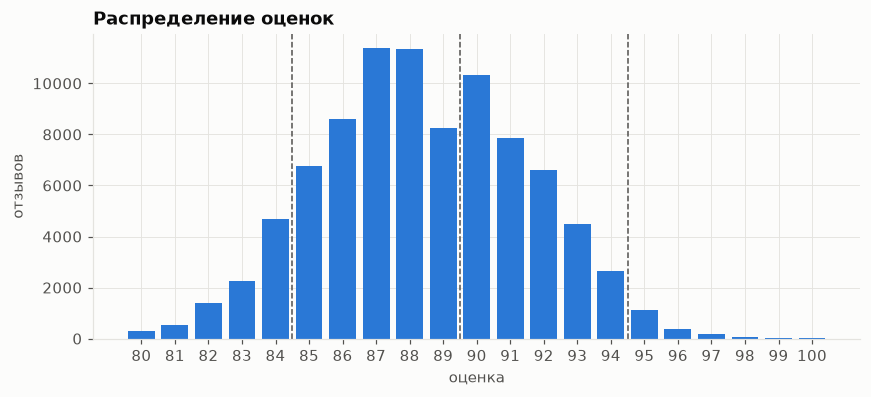

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.6))
counts = df[POINTS_COL].value_counts().sort_index()
ax.bar(counts.index, counts.values, width=0.8, color=MAIN)
for b in (84.5, 89.5, 94.5):
    ax.axvline(b, color=TEXT_MUTED, lw=1, ls="--")
ax.set_xticks(counts.index)
ax.set_xlabel("оценка")
ax.set_ylabel("отзывов")
ax.set_title("Распределение оценок")
save(fig, "eda_points_hist")
plt.show()

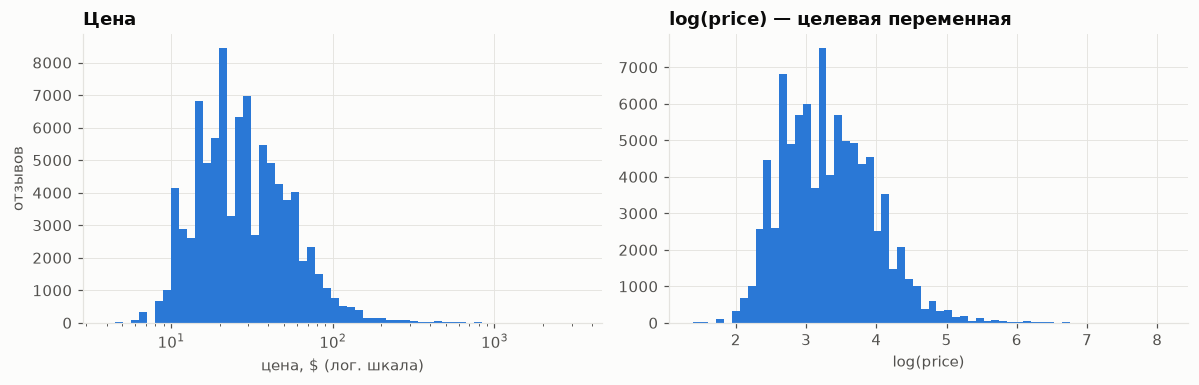

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(df[PRICE_COL], bins=np.logspace(np.log10(4), np.log10(df[PRICE_COL].max()), 60), color=MAIN)
axes[0].set_xscale("log")
axes[0].set_xlabel("цена, $ (лог. шкала)")
axes[0].set_ylabel("отзывов")
axes[0].set_title("Цена")

axes[1].hist(df[LOG_PRICE_COL], bins=60, color=MAIN)
axes[1].set_xlabel("log(price)")
axes[1].set_title("log(price) — целевая переменная")
fig.tight_layout()
save(fig, "eda_price_hist")
plt.show()

## 2. Связь оценки и цены

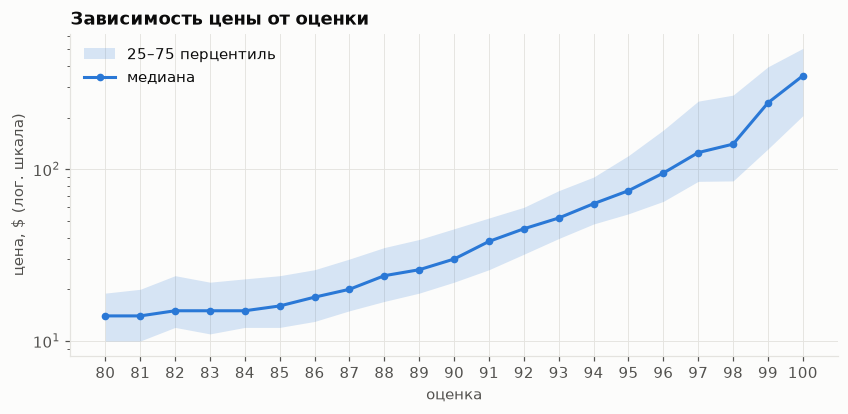

In [14]:
pearson = stats.pearsonr(df[POINTS_COL], df[LOG_PRICE_COL])[0]
spearman = stats.spearmanr(df[POINTS_COL], df[LOG_PRICE_COL])[0]

by_pts = df.groupby(POINTS_COL)[PRICE_COL].agg(["median", lambda s: s.quantile(.25), lambda s: s.quantile(.75), "size"])
by_pts.columns = ["median", "q25", "q75", "n"]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.fill_between(by_pts.index, by_pts.q25, by_pts.q75, color=MAIN, alpha=0.18, lw=0, label="25–75 перцентиль")
ax.plot(by_pts.index, by_pts["median"], color=MAIN, marker="o", ms=4, label="медиана")
ax.set_yscale("log")
ax.set_xticks(by_pts.index)
ax.set_xlabel("оценка")
ax.set_ylabel("цена, $ (лог. шкала)")
ax.set_title("Зависимость цены от оценки")
ax.legend(loc="upper left")
save(fig, "eda_price_by_points")
plt.show()

## 3. Текст отзыва

In [16]:
df["n_words"] = df[TEXT_COL].str.split().str.len()
df["n_chars"] = df[TEXT_COL].str.len()
print(df[["n_words", "n_chars"]].describe().round(1).T)

r_len = stats.spearmanr(df["n_words"], df[POINTS_COL])[0]
r_len_price = stats.spearmanr(df["n_words"], df[LOG_PRICE_COL])[0]
print(f"\nSpearman(длина в словах, points) = {r_len:.3f}")
print(f"Spearman(длина в словах, log price) = {r_len_price:.3f}")

           count   mean   std   min    25%    50%    75%    max
n_words  89253.0   40.7  11.3   3.0   33.0   40.0   47.0  135.0
n_chars  89253.0  244.5  67.4  20.0  198.0  239.0  285.0  829.0

Spearman(длина в словах, points) = 0.529
Spearman(длина в словах, log price) = 0.343


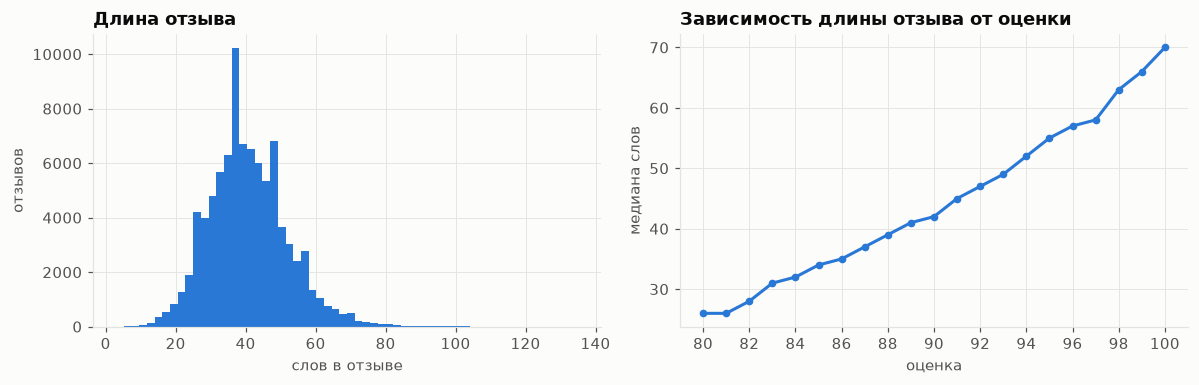

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(df["n_words"], bins=60, color=MAIN)
axes[0].set_xlabel("слов в отзыве")
axes[0].set_ylabel("отзывов")
axes[0].set_title("Длина отзыва")

len_by_pts = df.groupby(POINTS_COL)["n_words"].median()
axes[1].plot(len_by_pts.index, len_by_pts.values, color=MAIN, marker="o", ms=4)
axes[1].set_xticks(len_by_pts.index[::2])
axes[1].set_xlabel("оценка")
axes[1].set_ylabel("медиана слов")
axes[1].set_title("Зависимость длины отзыва от оценки")
fig.tight_layout()
save(fig, "eda_text_length")
plt.show()

Длина в токенах RoBERTa на случайной выборке из 5 000 отзывов: нужна для выбора `max_length` при дообучении

In [18]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("roberta-base")
sample = df.sample(5000, random_state=SEED)
n_tok = pd.Series([len(ids) for ids in tok(sample[TEXT_COL].tolist())["input_ids"]])

meta_prefix = ("Country: " + sample["country"].fillna("") + ". Variety: " + sample["variety"].fillna("")
               + ". Province: " + sample["province"].fillna("") + ". Description: ")
n_tok_meta = pd.Series([len(ids) for ids in tok((meta_prefix + sample[TEXT_COL]).tolist())["input_ids"]])

q = [.5, .9, .95, .99, 1.0]
tok_table = pd.DataFrame({"только текст": n_tok.quantile(q), "текст + метаданные": n_tok_meta.quantile(q)}).round(0)
tok_table.index = ["медиана", "p90", "p95", "p99", "max"]
display(tok_table)
for L in (128, 160, 192, 256):
    print(f"max_length={L}: обрезается {(n_tok > L).mean():.2%} текстов, {(n_tok_meta > L).mean():.2%} с метаданными")

,только текст,текст + метаданные
медиана,58.0,76.0
p90,81.0,98.0
p95,88.0,105.0
p99,100.0,118.0
max,144.0,160.0


max_length=128: обрезается 0.12% текстов, 0.26% с метаданными
max_length=160: обрезается 0.00% текстов, 0.00% с метаданными
max_length=192: обрезается 0.00% текстов, 0.00% с метаданными
max_length=256: обрезается 0.00% текстов, 0.00% с метаданными


## 4. Метаданные

In [19]:
meta = pd.DataFrame({
    "пропусков": df[META_COLS].isna().sum(),
    "доля пропусков": df[META_COLS].isna().mean().round(3),
    "уникальных": df[META_COLS].nunique(),
    "доля топ-10": [df[c].value_counts(normalize=True).head(10).sum().round(3) for c in META_COLS],
})
meta

,пропусков,доля пропусков,уникальных,доля топ-10
country,38,0.000,41,0.958
province,38,0.000,404,0.623
region_1,14389,0.161,1174,0.259
variety,1,0.000,658,0.558
winery,0,0.000,14852,0.015
taster_name,18644,0.209,19,0.921


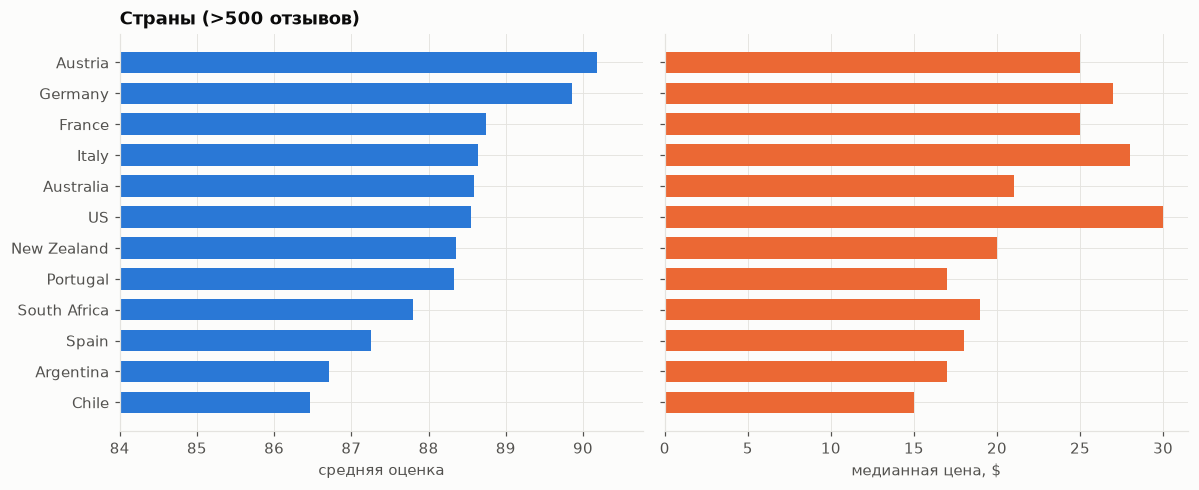

In [25]:
def effect_table(col, min_n=500):
    """Средние оценка и цена по категориям с достаточным числом отзывов."""
    g = df.groupby(col).agg(n=(POINTS_COL, "size"), points=(POINTS_COL, "mean"),
                            price_median=(PRICE_COL, "median"))
    return g[g.n >= min_n].sort_values("points")


def plot_effect(col, title, fname, min_n=500):
    t = effect_table(col, min_n)
    fig, axes = plt.subplots(1, 2, figsize=(11, 0.28 * len(t) + 1.2), sharey=True)
    axes[0].barh(t.index, t.points - 80, left=80, color=MAIN, height=0.7)
    # axes[0].axvline(df[POINTS_COL].mean(), color=TEXT_MUTED, lw=1, ls="--")
    axes[0].set_xlim(84, t.points.max() + 0.6)
    axes[0].set_xlabel("средняя оценка")
    axes[1].barh(t.index, t.price_median, color=PALETTE[1], height=0.7)
    axes[1].set_xlabel("медианная цена, $")
    axes[0].set_title(title)
    fig.tight_layout()
    save(fig, fname)
    plt.show()
    return t


plot_effect("country", f"Страны (>500 отзывов)", "eda_by_country");

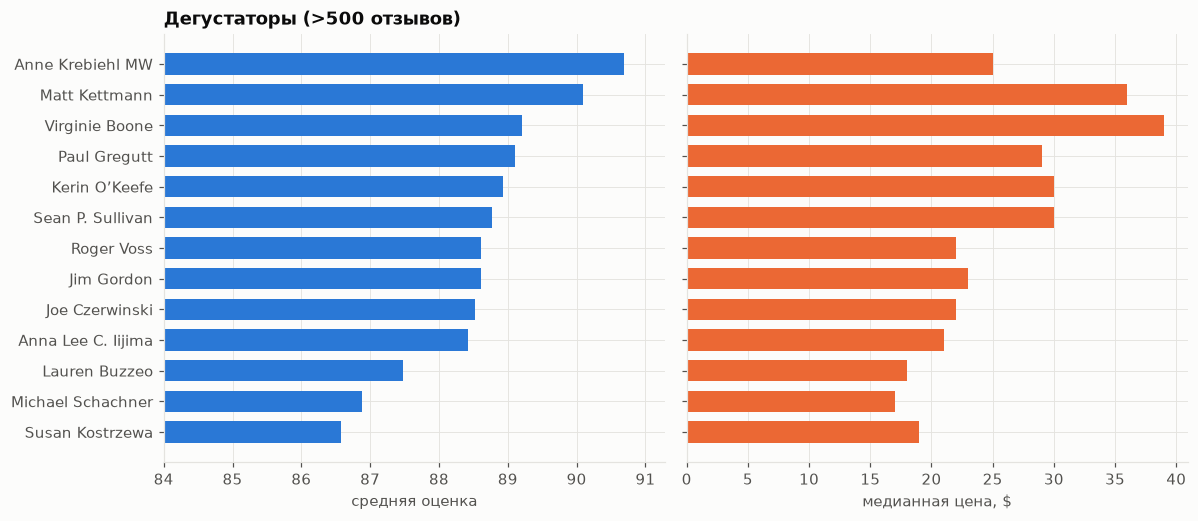

In [24]:
plot_effect("taster_name", "Дегустаторы (>500 отзывов)", "eda_by_taster");

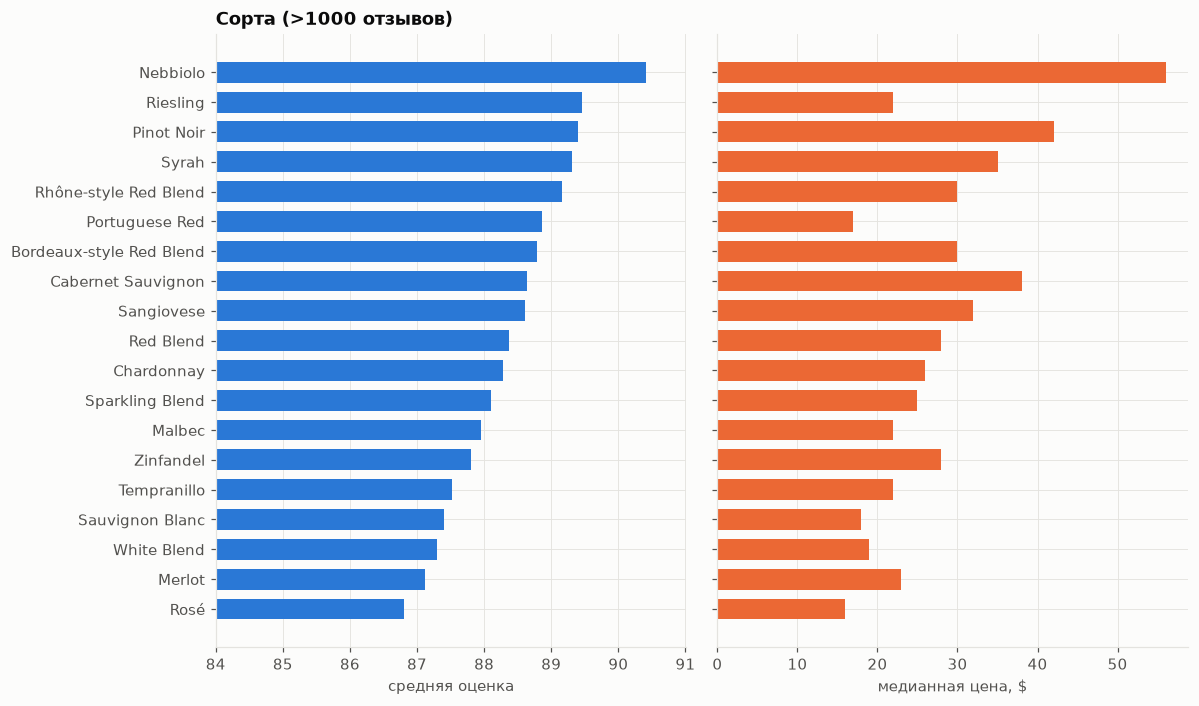

In [23]:
plot_effect("variety", "Сорта (>1000 отзывов)", "eda_by_variety", min_n=1000);

In [ ]:
# какую долю дисперсии оценки и цены объясняет каждый признак сам по себе
def eta2(col, target):
    s = df[col].fillna("NA")
    vc = s.value_counts()
    s = s.where(s.map(vc) >= 30, "other")
    means = df.groupby(s)[target].transform("mean")
    return 1 - ((df[target] - means) ** 2).sum() / ((df[target] - df[target].mean()) ** 2).sum()

pd.DataFrame({
    "eta² points": [eta2(c, POINTS_COL) for c in META_COLS],
    "eta² log price": [eta2(c, LOG_PRICE_COL) for c in META_COLS],
}, index=META_COLS).round(3).sort_values("eta² log price", ascending=False)

,eta² points,eta² log price
region_1,0.187,0.363
variety,0.088,0.208
province,0.108,0.195
winery,0.101,0.133
taster_name,0.088,0.086
country,0.050,0.078


## 5. Баланс классов

In [27]:
cls = pd.DataFrame({
    "2 класса": points_to_class(df[POINTS_COL], 2).value_counts(normalize=True).sort_index(),
    "4 класса": points_to_class(df[POINTS_COL], 4).value_counts(normalize=True).sort_index(),
}).round(3)
cls.index = ["0", "1", "2", "3"]
cls

,2 класса,4 класса
0,0.623,0.103
1,0.377,0.519
2,NaN,0.358
3,NaN,0.020


In [28]:
p2 = points_to_class(df[POINTS_COL], 2).value_counts(normalize=True).max()
p4 = points_to_class(df[POINTS_COL], 4).value_counts(normalize=True).max()
print(f"accuracy константного классификатора: 2 класса = {p2:.3f}, 4 класса = {p4:.3f}")
print("ориентир JWE 2022 (BERT): 0.89 и 0.82")

accuracy константного классификатора: 2 класса = 0.623, 4 класса = 0.519
ориентир JWE 2022 (BERT): 0.89 и 0.82


## 6. Слова высоких и низких оценок

Лог-отношение частот слов в отзывах 95+ и 80–84 (сглаживание +1, слова с частотой ≥ 20).

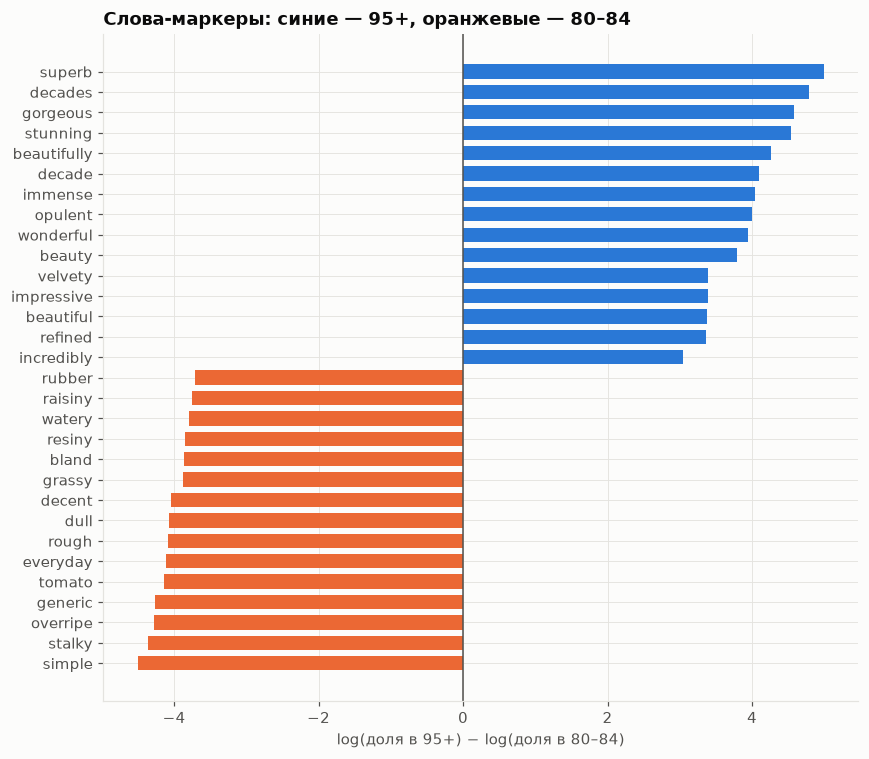

отзывов 95+: 1751, 80–84: 9207


In [29]:
from sklearn.feature_extraction.text import CountVectorizer

vec = CountVectorizer(stop_words="english", min_df=20, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b")
X = vec.fit_transform(df[TEXT_COL])
vocab = np.array(vec.get_feature_names_out())

hi = (df[POINTS_COL] >= 95).values
lo = (df[POINTS_COL] <= 84).values
f_hi = np.asarray(X[hi].sum(0)).ravel() + 1
f_lo = np.asarray(X[lo].sum(0)).ravel() + 1
log_ratio = np.log(f_hi / f_hi.sum()) - np.log(f_lo / f_lo.sum())
mask = (f_hi + f_lo) >= 40
lr = pd.Series(log_ratio[mask], index=vocab[mask]).sort_values()

words = pd.concat([lr.head(15), lr.tail(15)])
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(words.index, words.values, color=[PALETTE[1] if v < 0 else MAIN for v in words.values], height=0.7)
ax.axvline(0, color=TEXT_MUTED, lw=1)
ax.set_xlabel("log(доля в 95+) − log(доля в 80–84)")
ax.set_title("Слова-маркеры: синие — 95+, оранжевые — 80–84")
fig.tight_layout()
save(fig, "eda_words_hi_lo")
plt.show()
print(f"отзывов 95+: {hi.sum()}, 80–84: {lo.sum()}")

In [30]:
# примеры отзывов с крайними оценками
pd.concat([df[df[POINTS_COL] >= 98].sample(2, random_state=SEED),
           df[df[POINTS_COL] <= 80].sample(2, random_state=SEED)])[[POINTS_COL, PRICE_COL, "variety", TEXT_COL]]

,points,price,variety,description
24584,98,235.0,Red Blend,"Red berry, cedar and light spice aromas lead the way on this dazzling red. The vibrant palate is loaded with finesse, delivering bright red curran..."
105156,98,70.0,Cabernet Sauvignon,"So enormously delicious, it will be hard to keep from drinking this gorgeous Cabernet right away, and that's just fine. It's composed of the most ..."
85120,80,19.0,Sauvignon Blanc,"Dull and vegetal. Tastes like canned asparagus juice, with a squeeze of citrus."
48888,80,15.0,Cabernet Sauvignon,Raw cherry and plum aromas are resiny and suggest wet cement. This is shearing and so jacked up with tartaric acidity that it's almost intolerable...


## 7. Выводы

**Целевые переменные**
- Оценки лежат в узком диапазоне: среднее 88.4, std 3.1, 65% отзывов в 86–91, 95+ всего 2%. Значит, модель «предсказать среднее» уже даёт RMSE ≈ 3.1, и именно с этим числом сравниваем все модели
- Цена сильно скошена, поэтому `log(price)` подходит как целевая переменная
- Оценка и log(price) достаточно связаны

**Текст**
- Отзывы короткие: медиана 40 слов, 58 токенов RoBERTa, p99 = 100 токенов. **`max_length=128` обрезает 0.1% текстов** (0.3% с метаданными в тексте), поэтому 128 хватит и для экспериментов
- Длина отзыва сама по себе сильно связана с оценкой
- Лексика чётко разделяет полюса: 95+ — *superb, gorgeous, stunning, decades* (потенциал выдержки), 80–84 — *simple, generic, dull, watery, overripe*. Задача хорошо подходит для текстовых моделей

**Метаданные**
- По отдельности метаданные объясняют цену заметно лучше, чем оценку. Скорее всего, метаданные сильнее помогут при предсказании цены
- Дегустаторы заметно различаются по средней оценке. Это систематическое смещение, и текст его, скорее всего, передаёт лишь частично
- `winery` имеет 15 тыс. уникальных значений, нужно будет внимательно следить за переобучением на этом признаке